## Homework 6 Problem 3 <br>
Filippa Mudsam

**part (c)**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
R0i = np.linspace(0.5, 3, 200)

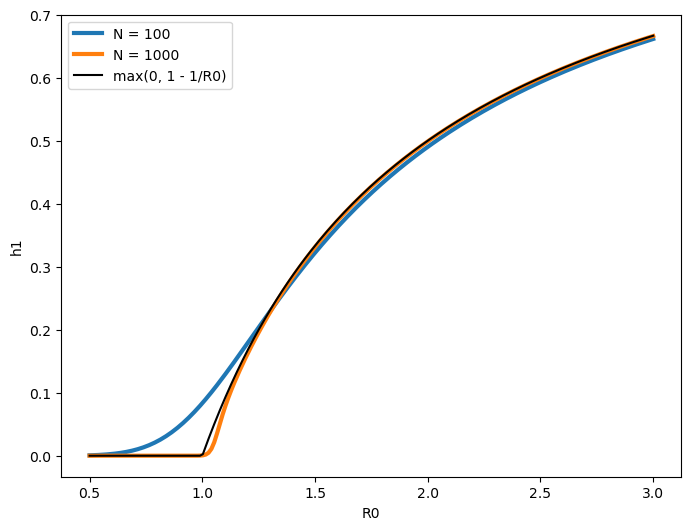

In [9]:
plt.figure(1, figsize = (8,6))

for N in [100,1000]:
    K = N//10 #int for K size
    h1 = np.zeros(len(R0i))

    for k in range(len(R0i)):
        R0 = R0i[k]

        rho = np.zeros(K)
        rho[0]=1
        for j in range(1, K):
            rho[j] = rho[j-1]*N / (R0*(N-j))

        h1[k] = 1/np.sum(rho)

    plt.plot(R0i, h1, linewidth=3)

plt.plot(R0i, np.maximum(0, 1 - 1/R0i), 'black')
plt.xlabel('R0')
plt.ylabel('h1')
plt.legend(['N = 100', 'N = 1000', 'max(0, 1 - 1/R0)'])
plt.show()

**part (d)**

In [10]:
rng = np.random.default_rng()

N = 100
K = 10
g = 1
dt = 0.005

In [11]:
for R0 in [0.5, 0.8, 1.5, 3]:
    b = R0*g/N     
 
   
    pn = np.zeros(K+1)
    qn = np.zeros(K+1)
    for n in range(1, K):
        pn[n] = b*n*(N - n)*dt
        qn[n] = g*n*dt
 
    #tridiagonal
    A = np.zeros((K-1, K-1))
    for n in range(1, K):
        A[n-1, n-1] = pn[n] + qn[n]
        if n > 1:
            A[n-1, n-2] = -qn[n]
        if n < K-1:
            A[n-1, n] = -pn[n]
    e = np.linalg.solve(A, np.ones(K-1))
 
    print('R0 = %.1f   e1*dt = %.4f' % (R0, e[0]*dt))

R0 = 0.5   e1*dt = 1.3736
R0 = 0.8   e1*dt = 1.7699
R0 = 1.5   e1*dt = 1.7959
R0 = 3.0   e1*dt = 0.9655


In [18]:
#choosing R0 value for {.5,.8,1.5,3}
R0 = 1.5

In [13]:
b = R0*g/N
pn = np.zeros(K+1)
qn = np.zeros(K+1)

In [14]:
for n in range(1, K):
    pn[n] = b*n*(N - n)*dt
    qn[n] = g*n*dt

In [15]:
Nsim = 2000
Ts = np.zeros(Nsim)

In [16]:
for k in range(Nsim):
    n = 1
    t = 0
    while n > 0 and n < K:
        u = rng.random()
        if u < qn[n]:
            n = n - 1
        elif u < qn[n] + pn[n]:
            n = n + 1
        t = t + 1
    Ts[k] = t

In [ ]:
print('simulation, R0 = 1.5:   e1*dt = %.4f' % (np.mean(Ts)*dt))

simulation, R0 = 1.5:   e1*dt = 1.8733
